# 03 — Remaining life: how many cycles are left, and how sure are we?

**Stand-in data.** NASA turbofan simulation data stands in for rotating equipment. Not real field data.

**Phase 3 "done" line:** results table, baselines vs main model, all with engine-grouped validation.

**Models** (code in `src/rul.py`, features in `src/features.py`, settings in `configs/config.yaml` → `rul:`):
1. **Mean baseline:** always predict the average training RUL.
2. **Linear regression** on the 14 current sensor readings.
3. **LightGBM** on 141 backward-looking features: rolling mean / std / slope over 5, 10, 20 cycles, distance from
   the engine's own healthy start, and cycle number. Fixed, untuned settings.
4. **Confidence range:** LightGBM 5% and 95% quantile models, then **cross-conformal calibration**: every training
   engine gets an out-of-fold range; how far the truth falls outside those ranges sets a margin that widens every range
   until it covers 90%.

Training target = RUL capped at 125. Evaluation uses **true** RUL.

**Metrics:** RMSE (typical error, cycles) · NASA score (late calls punished more than early; lower is better) ·
coverage (share of truths inside the range; target 90%) · width (cycles).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
print("interpreter:", sys.executable)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import SENSORS, add_rul, add_test_rul, load_config, load_fd, near_constant_columns
from src.features import add_rolling_features
from src.rul import cross_validate, fit_predict, summarize

cfg = load_config()
CAP = cfg["data"]["rul_cap"]
FIG_DIR = ROOT / cfg["paths"]["figures"]
train, test, true_rul = load_fd(cfg["data"]["subset"])
train, test = add_rul(train, CAP), add_test_rul(test, true_rul, CAP)
sensors = [s for s in SENSORS if s not in near_constant_columns(train, cfg["data"]["near_constant_std"])]
feat_args = (sensors, cfg["features"]["window_sizes"], cfg["anomaly"]["baseline_cycles"])
train, features = add_rolling_features(train, *feat_args)
test, _ = add_rolling_features(test, *feat_args)

BLUE, ORANGE, GRAY, INK, INK2 = "#2a78d6", "#eb6834", "#b5b4ae", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRAY,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "font.size": 9,
})
print(f"{len(features)} features from {len(sensors)} sensors")

interpreter: C:\Users\A\Documents\NASA-project\.venv\Scripts\python.exe


141 features from 14 sensors


## 1. Cross-validation on train engines (5 folds, split by engine)

Scored on rows with true RUL ≤ 125: where maintenance decisions happen and the cap doesn't distort error.
`nasa_mean` = average penalty per prediction (row counts differ from the test set, so sums aren't comparable).

In [2]:
cv = cross_validate(train, features, sensors, cfg)
near = cv[cv.rul <= CAP]
cv_point, cv_interval = summarize(near)
print("conformal margin per fold (cycles):", cv.margin.unique().round(2))
display(cv_point[["rmse", "nasa_mean", "n"]].round(2))
display(cv_interval.round(3))

conformal margin per fold (cycles): [5.04 4.68 4.48 5.38 4.33]


,rmse,nasa_mean,n
mean,43.76,493.00,12600.0
linear,21.79,12.24,12600.0
lgbm,12.20,2.84,12600.0


,coverage,mean_width
quantile_raw,0.767,39.341
conformal,0.911,48.758


## 2. Official test set (used once, at the end)

One prediction per test engine at its last observed cycle, compared with `RUL_FD001.txt`.
`nasa_sum` over the 100 engines is the number published work reports.

*Honesty note:* the test set was scored twice during development — once with the first LightGBM settings
(500 trees, RMSE 12.76) and once with the final ones (250 trees + coarser bins, chosen for 4× speed; and the
calibration switched from a 25% hold-out to cross-conformal because CV coverage was 84%). Neither change was made
because of the test score. Numbers below are the final settings.

In [3]:
last = test.groupby("engine").tail(1)
tp = fit_predict(train, last, features, sensors, cfg)
res = pd.concat([last[["engine", "rul"]], tp], axis=1).set_index("engine")
test_point, test_interval = summarize(res)
print(f"conformal margin: {tp.attrs['margin']:.2f} cycles")
display(test_point[["rmse", "nasa_sum", "n"]].round(2))
display(test_interval.round(3))
near_t = res[res.rul <= CAP]
print(f"test engines with true RUL <= {CAP}: n = {len(near_t)}")
display(pd.concat(summarize(near_t), axis=1).loc[:, ["rmse", "coverage", "mean_width"]].dropna(how="all").round(3))

conformal margin: 3.99 cycles


,rmse,nasa_sum,n
mean,43.07,33629.23,100.0
linear,21.90,1313.99,100.0
lgbm,13.14,236.26,100.0


,coverage,mean_width
quantile_raw,0.75,43.044
conformal,0.89,51.017


test engines with true RUL <= 125: n = 89


,rmse,coverage,mean_width
mean,42.385,NaN,NaN
linear,20.819,NaN,NaN
lgbm,11.937,NaN,NaN
quantile_raw,NaN,0.843,43.485
conformal,NaN,0.966,51.458


## 3. Every test engine: prediction, range, truth

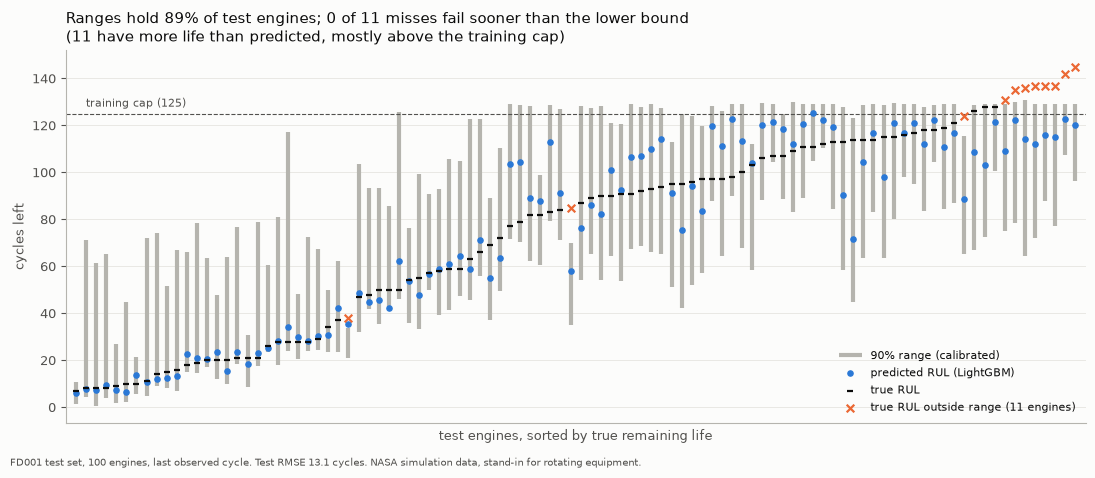

misses: engine 91 (true 38, range 21-34), engine 93 (true 85, range 35-70), engine 12 (true 124, range 65-115), engine 73 (true 131, range 75-129), engine 47 (true 135, range 79-130), engine 89 (true 136, range 65-131), engine 55 (true 137, range 72-129), engine 96 (true 137, range 88-129), engine 83 (true 137, range 77-129), engine 39 (true 142, range 107-129), engine 25 (true 145, range 96-129)


In [4]:
r = res.sort_values("rul").reset_index()
x = np.arange(len(r))
miss = (r.rul < r.lo) | (r.rul > r.hi)

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.vlines(x, r.lo, r.hi, color=GRAY, linewidth=3, label="90% range (calibrated)")
ax.scatter(x, r.lgbm, s=14, color=BLUE, zorder=3, label="predicted RUL (LightGBM)")
ax.scatter(x[~miss], r.rul[~miss], s=22, marker="_", color=INK, linewidths=1.6, zorder=4, label="true RUL")
ax.scatter(x[miss], r.rul[miss], s=30, marker="x", color=ORANGE, linewidths=1.6, zorder=4,
           label=f"true RUL outside range ({miss.sum()} engines)")
ax.axhline(CAP, color=INK2, linewidth=0.8, linestyle="--")
ax.text(1, CAP + 3, f"training cap ({CAP})", color=INK2, fontsize=8)
ax.set(xlabel="test engines, sorted by true remaining life", ylabel="cycles left", xlim=(-1, len(r)), xticks=[])
late_miss = int((r.rul < r.lo).sum())  # truth below the lower bound = failure sooner than warned (dangerous side)
ax.set_title(f"Ranges hold {1 - miss.mean():.0%} of test engines; {late_miss} of {miss.sum()} misses fail sooner than the lower bound\n"
             f"({(r.rul > r.hi).sum()} have more life than predicted, mostly above the training cap)",
             loc="left", fontsize=11)
ax.legend(loc="lower right", frameon=False, fontsize=8)
fig.text(0.01, -0.02, f"FD001 test set, 100 engines, last observed cycle. Test RMSE {test_point.loc['lgbm', 'rmse']:.1f} cycles. "
         "NASA simulation data, stand-in for rotating equipment.", fontsize=7, color=INK2)
fig.tight_layout()
fig.savefig(FIG_DIR / "rul_test_intervals.png", dpi=130, bbox_inches="tight")
plt.show()
print("misses:", ", ".join(f"engine {e} (true {t}, range {l:.0f}-{h:.0f})" for e, t, l, h in r.loc[miss, ["engine", "rul", "lo", "hi"]].itertuples(index=False)))

## 4. Where is the model accurate? Error by true remaining life (CV)

bias = mean(predicted − true): positive = late (claims more life than real), the dangerous direction.

In [5]:
bins = [0, 25, 50, 75, 100, CAP]
near = near.assign(err=near.lgbm - near.rul, bucket=pd.cut(near.rul, bins, include_lowest=True))
by = near.groupby("bucket", observed=True).agg(
    rows=("err", "size"), bias=("err", "mean"), rmse=("err", lambda e: np.sqrt((e**2).mean())),
    range_coverage=("rul", lambda s: ((s >= near.loc[s.index, "lo"]) & (s <= near.loc[s.index, "hi"])).mean()),
    range_width=("lo", lambda s: (near.loc[s.index, "hi"] - s).mean()),
)
by.round(2)

,rows,bias,rmse,range_coverage,range_width
bucket,,,,,
"(-0.001, 25.0]",2600,1.01,3.65,0.98,31.95
"(25.0, 50.0]",2500,2.82,7.99,0.89,47.94
"(50.0, 75.0]",2500,6.74,15.22,0.87,58.88
"(75.0, 100.0]",2500,6.55,16.32,0.90,57.08
"(100.0, 125.0]",2500,-3.38,13.22,0.91,48.61


## 5. Coverage per engine (CV)

90% coverage is an **average over rows**. Is it spread evenly, or do some engines' ranges keep missing?

In [6]:
per_eng = near.assign(inside=(near.rul >= near.lo) & (near.rul <= near.hi)).groupby("engine").inside.mean()
print(per_eng.describe().round(2).to_string())
print(f"engines whose range holds the truth less than half the time: {(per_eng < 0.5).sum()} of {len(per_eng)}")

count    100.00
mean       0.91
std        0.17
min        0.31
25%        0.93
50%        0.98
75%        1.00
max        1.00
engines whose range holds the truth less than half the time: 7 of 100


## 6. Leakage checks

- **Engine split:** CV folds and the inner calibration folds both use `engine_folds` (GroupKFold) — no engine on both sides (tested).
- **No look-ahead:** every feature at cycle t uses cycles ≤ t only, including the healthy-baseline average (tested: changing
  a future row leaves past features unchanged).
- **Calibration:** each training engine's range comes from quantile models that never saw that engine.
- **Test set:** never used to fit, tune or calibrate. Scored twice; see the honesty note in section 2.
- **CV vs test agree** (RMSE ~12 vs ~13): no sign the CV score is inflated.

## 7. Conclusions

### Results table (true RUL; CV = 5-fold engine-grouped on train, rows with RUL ≤ 125)

| Model | CV RMSE | CV NASA (mean/prediction) | Test RMSE | Test NASA (sum, 100 engines) |
|---|---|---|---|---|
| Mean baseline | 43.8 | 493 | 43.1 | 33,629 |
| Linear regression (current sensors) | 21.8 | 12.2 | 21.9 | 1,314 |
| Ridge regression (same rolling features as LightGBM) | 18.0 | 5.91 | 17.7 | 458 |
| **LightGBM (rolling features)** | **12.2** | **2.84** | **13.1** | **236** |

| Confidence range (target 90%) | CV coverage | CV width | Test coverage | Test width |
|---|---|---|---|---|
| Raw LightGBM quantiles | 76.7% | 39.3 | 75% | 43.0 |
| **After cross-conformal calibration** | **91.1%** | **48.8** | **89%** | **51.0** |

1. **LightGBM cuts error by ~45% vs linear regression on current readings** (RMSE 21.8 → 12.2 in CV), but part of that gain comes from the rolling features, not the model. Against a linear model given the *same* features (ridge, added after review: CV 18.0, test 17.7), LightGBM's own gain is ~26–32% and the NASA score halves (test 458 → 236). CV and test agree (12.2 vs 13.1), so the CV score is not inflated.
2. **Raw quantile models are overconfident** (a "90%" range covered ~76%). Calibration fixes this: 91% in CV, 89% on test, at the cost of 8–9 extra cycles of width.
3. **Every test miss is on the safe side.** All 11 test engines outside their range had *more* life than the upper bound — 8 of them above the 125 training cap, which a capped model cannot reach by design. No test engine failed sooner than its lower bound. This matters for Phase 5, where the lower bound triggers maintenance.
4. **Accuracy is best where it matters most.** With ≤ 25 cycles left: RMSE 3.7, range covers 98%, width 32. With 50–100 cycles left: RMSE ~15–16 and a late bias of ~+7 cycles (claims more life than real) — the uncertain middle of life.
5. **The first split-conformal attempt failed honestly:** holding back 25% of engines (20) gave 84% CV coverage, because coverage varies hugely between engines and 20 is too few to calibrate on. Cross-conformal (calibrating on out-of-fold ranges from all training engines) fixed it.

### Limits
- **Coverage is an average, not a per-engine promise.** Median engine: 98% of its rows covered; worst engine: 31%; 7 of 100 engines are covered less than half the time.
- **The 90% applies to engines with 125 cycles or fewer left.** The margin was calibrated on rows with true remaining life ≤ 125 (where maintenance decisions happen). Above the cap, ranges under-cover by design: 8 of the 11 test misses are engines with more than 125 cycles left.
- **Capped at 125.** The model never predicts much above 125, so engines with longer remaining life look shorter-lived. Fine for maintenance decisions (they're far from failure), but don't read it as a real life estimate there.
- **Test set scored twice** during development (see section 2); settings were not changed because of it.
- **Simulation data**, one operating condition, one fault mode. Real-world error will be larger.
- **Deep learning (CNN/LSTM) not tried.** Stretch goal (Colab only); worth it only if a clear gain over LightGBM shows up.
